# 09 Rainfall, onset seasonality and the next-event forecast

```
Created on Mon Sep 21 2026
@author: daniellelindsay
Run in opera_disp_feb13. The forecast mixture takes ~5 min.
```

**What this notebook does.**

1. **Daily rain at Tule Pond** from the NOAA GHCN-daily gauges, spliced day
   by day in the order Fremont > Newark > Hayward Air Terminal (no rescaling;
   the overlaps are documented). Morning-observer COOP gauges are shifted one
   day earlier onto the midnight basis. Water year Oct 1 to Sep 30, named by
   the year it ends. The gauge files in `Inputs/GHCN_daily` are the frozen
   inputs; they are only downloaded if missing.
2. **Onset seasonality**: every season-resolved onset (the 5 InSAR windows,
   the 9 array windows of 130 d or less) on the water year over the rain.
3. **Renewal forecast** of the next onset: onsets drawn uniformly within
   their windows (no midpoints), intervals fitted by exponential, lognormal,
   Weibull, BPT and Gaussian models with a parametric bootstrap, conditional
   on no event by the reference date. Four catalogues: InSAR only, the
   dense-era array record (with and without the Loma Prieta interval), and
   the merged record. The issue date is pinned so the numbers reproduce.
4. **Rainfall conditioning**: for each onset, the water-year rain accumulated
   by then, the lag after fixed cumulative thresholds (rule A) and after the
   first storm of the year (rule B), and the storm-proximity test (rule C)
   scored against its wet-season base rate. The prediction statement combines
   the recurrence window with the calendar window.

Ported from `Hayward_DISP-S1/analysis/run20_precip_ghcn.py`,
`run21_recurrence_forecast.py`, `run22_precip_conditioning.py` and
`plotting/fig_hrkt_onset_seasonality.py`.

**Outputs** (`outputs/09_seasonality_forecast/`): `tulepond_daily_precip.csv`,
`wateryear_totals.csv`, `recurrence_forecast_models.csv`,
`precip_conditioning_{events,thresholds,ruleC}.csv`, `prediction_statement.txt`,
`09_forecast_stats.txt`, registry rows `09_*`.

**Figures**: Fig 3 bottom (onsets on the water year over the rain), Fig 4
(repeat intervals and the next-onset forecast), the conditioning figure (S).

**What to check.** InSAR onsets fall Dec 13 to Mar 9; the InSAR clock gives
the next event about mid December 2026 with a 95% prediction interval of
late August 2026 to early April 2027; the array record gives ~28% for the
same wet season. Rule C: a 40 mm storm within 21 d of all five onsets.

In [1]:
import os
import urllib.request
from datetime import datetime

import insar_utils as utils
from TulePond_filepaths import common_paths, segments, paths_out, repo_dir, forecast_issue_date

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

## Constants

In [2]:
notebook = "09_seasonality_forecast"
out_dir = paths_out[notebook]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the gauges: id -> (short name, role in the composite, day shift for morning-observer COOP gauges)
ncei = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{sid}.csv"
stations = {"USC00043244": ("FREMONT", "composite-1", 0),      # COOP but on the midnight basis (checked against Hayward)
            "USC00046144": ("NEWARK", "composite-2", -1),      # COOP, morning observer
            "USW00093228": ("HAYWARD_AT", "composite-3", 0),   # ASOS, midnight basis
            "USC00044997": ("LIVERMORE", "alt", -1),
            "USW00023293": ("SAN_JOSE", "alt", 0),
            "USC00046336": ("OAKLAND_MUS", "alt", -1)}
composite = ["FREMONT", "NEWARK", "HAYWARD_AT"]
tulepond = (37.557, -121.970)      # section centre (lat, lon)
t_start = "1978-10-01"             # start of WY1979 (first HRKT survey 1979.7)
series_end = pd.Timestamp(forecast_issue_date)   # the rain series ends at the issue date so the run reproduces

# the forecast
resolvable_days = 130      # array windows longer than this do not constrain the season
loma_prieta = 1989.80
n_timing, n_boot, seed = 400, 5, 7
ref_dates = {"data_end": "2025-12-21", "issue": forecast_issue_date}
wet = ("2026-10-01", "2027-04-30")      # the coming wet season, WY2027
horizon = "2027-12-31"
models = ["exponential", "lognormal", "weibull", "bpt", "gaussian"]
grid = np.arange(2025.0, 2031.0, 1 / 365.25)

# the conditioning
y_grid = [50, 75, 100, 125, 150, 175, 200, 250, 300, 400]   # WY cumulative thresholds, mm
z_grid = [15, 20, 25, 30, 40, 50, 75]                       # first-storm sizes (3-day totals), mm
storm_days = 3
c_z, c_x = [20, 30, 40, 50], [7, 14, 21, 30]                # rule C storm size and lag
wy_years = (1980, 2026)
wet_dowy = (62, 182)               # Dec 1 to Mar 31 as day of water year

# the seasonality figure
density_days, density_max = 7, 80  # running 7-day total, mm at full colour
x0, x1 = 1981.5, 2026.5

events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["08_alignment_arrays"], "hrkt_aa_events.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(events_file, aa_events_file, *[os.path.join(common_paths["ghcn_dir"], f"{sid}.csv") for sid in stations])


def decyear(dates):
    """Decimal year of a DatetimeIndex, fraction of the actual year length."""
    d = pd.DatetimeIndex(dates)
    y0 = pd.to_datetime(d.year.astype(str) + "-01-01"); y1 = pd.to_datetime((d.year + 1).astype(str) + "-01-01")
    return d.year + (d - y0) / (y1 - y0)


def decyear_to_date(y):
    y = np.atleast_1d(np.asarray(y, float)); out = []
    for v in y:
        yr = int(np.floor(v)); a, b = datetime(yr, 1, 1), datetime(yr + 1, 1, 1)
        out.append(a + (v - yr) * (b - a))
    return pd.DatetimeIndex(out)


def water_year(dates):
    d = pd.DatetimeIndex(dates); return d.year + (d.month >= 10).astype(int)


def dowy(dates):
    """Day of water year: Oct 1 = 1."""
    d = pd.DatetimeIndex(dates); wy0 = pd.to_datetime((water_year(d) - 1).astype(str) + "-10-01")
    return (d - wy0).days + 1


def ymd(y):
    return decyear_to_date(y)[0].strftime("%Y-%m-%d")

Registry for 09_seasonality_forecast: run 29a9955e, git nogit+


## The daily rain composite

In [3]:
def fetch(sid):
    path = os.path.join(common_paths["ghcn_dir"], f"{sid}.csv")
    if not os.path.exists(path) or os.path.getsize(path) < 1000:
        print("downloading", sid); urllib.request.urlretrieve(ncei.format(sid=sid), path)
    d = pd.read_csv(path, usecols=["DATE", "LATITUDE", "LONGITUDE", "NAME", "PRCP"], low_memory=False)
    d["DATE"] = pd.to_datetime(d.DATE); d = d[d.DATE >= t_start]
    meta = dict(name=d.NAME.iloc[0], lat=float(d.LATITUDE.iloc[0]), lon=float(d.LONGITUDE.iloc[0]),
                first=d.DATE.min().date(), last=d.DATE.max().date())
    s = d.set_index("DATE").PRCP / 10.0          # tenths of mm -> mm
    s = s[~s.index.duplicated()]
    if stations[sid][2]:
        s.index = s.index + pd.Timedelta(days=stations[sid][2])
    return s, meta


days = pd.date_range(t_start, series_end, freq="D")
tab = pd.DataFrame(index=days); metas = {}
for sid, (nm, role, shift) in stations.items():
    s, meta = fetch(sid)
    tab[nm] = s.reindex(days)
    metas[nm] = dict(sid=sid, role=role, shift=shift, **meta, n_valid=int(s[s.index <= series_end].notna().sum()),
                     dist_km=np.hypot((meta["lat"] - tulepond[0]) * 111.19, (meta["lon"] - tulepond[1]) * 111.19 * np.cos(np.radians(tulepond[0]))))
tab["prcp_mm"] = np.nan; tab["src"] = "none"
for nm in composite:
    take = tab.prcp_mm.isna() & tab[nm].notna()
    tab.loc[take, "prcp_mm"] = tab.loc[take, nm]; tab.loc[take, "src"] = nm
tab["decyear"] = decyear(tab.index); tab["wy"] = water_year(tab.index); tab["dowy"] = dowy(tab.index)
tab.index.name = "date"
g = tab.groupby("wy")
wy = pd.DataFrame({"total_mm": g.prcp_mm.sum(min_count=1), "n_days": g.prcp_mm.count(),
                   "n_missing": g.prcp_mm.apply(lambda x: x.isna().sum()), "max_day_mm": g.prcp_mm.max(),
                   "src": g.src.agg(lambda x: "+".join(sorted(set(x) - {"none"})))})
for nm in [v[0] for v in stations.values()]:
    wy[f"{nm}_mm"] = g[nm].sum(min_count=1); wy[f"{nm}_ndays"] = g[nm].count()
wy["complete"] = wy.n_missing <= 20
tab.to_csv(os.path.join(out_dir, "tulepond_daily_precip.csv"), float_format="%.4f")
wy.to_csv(os.path.join(out_dir, "wateryear_totals.csv"), float_format="%.1f")

L = ["09 RAIN, SEASONALITY AND FORECAST", f"rain series {days[0].date()} to {days[-1].date()} (ends at the pinned issue date {forecast_issue_date})", "stations:"]
for nm, m in metas.items():
    L.append(f"  {nm:<12} {m['sid']}  {m['name']:<38} {m['dist_km']:5.1f} km  {m['first']}..{m['last']}  n={m['n_valid']}  [{m['role']}, day shift {m['shift']:+d}]")
n_src = tab.src.value_counts()
L.append("composite = first reporting gauge in the order " + " > ".join(composite) + ": " + ", ".join(f"{k} {v} d" for k, v in n_src.items()))
for a, b in [("FREMONT", "NEWARK"), ("FREMONT", "HAYWARD_AT"), ("NEWARK", "HAYWARD_AT")]:
    both = wy[(wy[f"{a}_ndays"] >= 350) & (wy[f"{b}_ndays"] >= 350)]
    ratio = both[f"{a}_mm"] / both[f"{b}_mm"]
    ov = tab[[a, b]].dropna(); ov = ov[ov.index.isin(tab.index[tab.wy.isin(both.index)])]
    big = ov[(ov[a] >= 10) | (ov[b] >= 10)]
    r_day = np.corrcoef(big[a], big[b])[0, 1] if len(big) > 10 else np.nan
    L.append(f"  {a}/{b}: {len(both)} complete WYs, WY-total ratio median {ratio.median():.2f} (range {ratio.min():.2f}-{ratio.max():.2f}); "
             f"same-day totals on days >= 10 mm: n={len(big)}, r={r_day:.2f}")
comp = wy[wy.complete & (wy.index >= 1980) & (wy.index <= 2025)]
L.append(f"WY1980-2025 complete years (n={len(comp)}): median {comp.total_mm.median():.0f} mm, 10-90% {comp.total_mm.quantile(.1):.0f}-{comp.total_mm.quantile(.9):.0f} mm")
print("\n".join(L))

# CHECK: the COOP observation-time shift. Newark (morning observer) should agree
# with Hayward Air Terminal (midnight) on storm days once shifted, not before.
raw_newark, _ = fetch("USC00046144")
raw_newark.index = raw_newark.index + pd.Timedelta(days=1)          # undo the shift
hay = tab["HAYWARD_AT"]
for lab, ser in (("as published", raw_newark), ("shifted -1 d", tab["NEWARK"])):
    both = pd.concat([ser.reindex(days), hay], axis=1).dropna(); both = both[(both.iloc[:, 0] >= 10) | (both.iloc[:, 1] >= 10)]
    print(f"Newark vs Hayward on storm days, {lab}: r = {np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1]:.2f} (n = {len(both)})")

09 RAIN, SEASONALITY AND FORECAST
rain series 1978-10-01 to 2026-08-25 (ends at the pinned issue date 2026-08-25)
stations:
  FREMONT      USC00043244  FREMONT, CA US                           4.4 km  1996-06-01..2026-08-21  n=10673  [composite-1, day shift +0]
  NEWARK       USC00046144  NEWARK, CA US                            7.2 km  1978-10-01..2021-01-15  n=15062  [composite-2, day shift -1]
  HAYWARD_AT   USW00093228  HAYWARD AIR TERMINAL, CA US             17.5 km  1998-09-19..2026-08-21  n=10191  [composite-3, day shift +0]
  LIVERMORE    USC00044997  LIVERMORE, CA US                        23.8 km  1978-10-01..2026-08-21  n=17211  [alt, day shift -1]
  SAN_JOSE     USW00023293  SAN JOSE, CA US                         22.3 km  1998-07-04..2026-08-21  n=10273  [alt, day shift +0]
  OAKLAND_MUS  USC00046336  OAKLAND MUSEUM, CA US                   37.3 km  1978-10-01..2026-08-21  n=16260  [alt, day shift -1]
composite = first reporting gauge in the order FREMONT > NEWARK > HAYWAR

Newark vs Hayward on storm days, as published: r = -0.24 (n = 413)
Newark vs Hayward on storm days, shifted -1 d: r = 0.44 (n = 361)


## The event catalogues

In [4]:
ev = pd.read_csv(events_file)
ins = ev[ev.segment == "TULEPOND"].sort_values("onset_yr").reset_index(drop=True)
aa = pd.read_csv(aa_events_file)
dense = aa[aa.window_days <= resolvable_days].reset_index(drop=True)
aa_pre = aa[aa.onset_yr < ins.onset_yr.min() - 0.3]
merged = pd.concat([aa_pre[["onset_yr", "onset_lo", "onset_hi"]], ins[["onset_yr", "onset_lo", "onset_hi"]]]).sort_values("onset_yr").reset_index(drop=True)
catalogs = {"A_insar": (ins, False), "B_aa_dense": (dense, False), "B_aa_dense_noLP": (dense, True), "C_merged": (merged, False)}
print(f"InSAR {len(ins)} events; array dense era {len(dense)} events (windows <= {resolvable_days} d); merged {len(merged)} events")

InSAR 5 events; array dense era 9 events (windows <= 130 d); merged 16 events


## Figure 3 (bottom): onsets on the water year over the rain

Each water year is a column filled with the running 7-day rain total; the
water year runs down the page from Oct 1. Onsets are bars bounding the
observation window only, no midpoint marker: the event is equally likely
anywhere inside its window. Annual-survey array detections (windows of 300
to 390 d) are omitted because they do not constrain the season.

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/fig3b_onset_seasonality_wateryear_density7d_vmax80mm.png


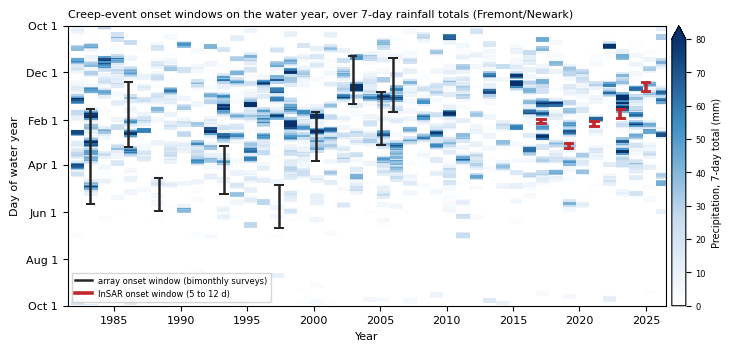

array resolvable: 9 (6 Dec-Mar); InSAR: 5 (5 Dec-Mar)


In [5]:
def dowy_frac(frac_year):
    return (((np.asarray(frac_year) % 1) * 365.25 - 274) % 365.25) + 1


def onset_bar(ax, x, lo, hi, color, lw):
    segs = [(lo, hi)] if hi >= lo else [(lo, 366), (1, hi)]
    for a, b in segs:
        ax.plot([x, x], [a, b], "-", color=color, lw=lw, solid_capstyle="butt", zorder=5)
    for y_ in (lo, hi):
        ax.plot([x - 0.28, x + 0.28], [y_, y_], "-", color=color, lw=lw * 0.8, zorder=5)


plt.rcParams.update({"font.size": 8})
fig, ax = plt.subplots(figsize=(7.2, 3.4), constrained_layout=True)
tab_p = tab[(tab.wy >= int(np.floor(x0)) + 1) & (tab.wy <= int(np.ceil(x1)))]
val = tab_p.prcp_mm.fillna(0).rolling(density_days, min_periods=1).sum()
wys = sorted(tab_p.wy.unique())
Z = np.full((367, len(wys)), np.nan); xe = []
for j, w_ in enumerate(wys):
    d = tab_p[tab_p.wy == w_]
    Z[d.dowy.values, j] = val[d.index].values
    xe.append(w_ - 1 + 273 / 365.25)
xe.append(wys[-1] + 273 / 365.25)
cmap = LinearSegmentedColormap.from_list("rain", ["#FFFFFF", "#C6DBEF", "#4292C6", "#08306B"])
pm = ax.pcolormesh(np.array(xe), np.arange(-0.5, 367.5), Z, cmap=cmap, vmin=0, vmax=density_max, shading="flat", rasterized=True, zorder=0)
for r in dense.itertuples():
    onset_bar(ax, r.onset_yr, dowy_frac(r.onset_lo), dowy_frac(r.onset_hi), "0.15", 1.8)
for r in ins.itertuples():
    onset_bar(ax, r.onset_yr, dowy_frac(r.onset_lo), dowy_frac(r.onset_hi), "#C1272D", 2.6)
ax.set_xlim(x0, x1); ax.set_ylim(366, 1)
ax.set_yticks([1, 62, 124, 182, 244, 305, 366]); ax.set_yticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_xlabel("Year"); ax.set_ylabel("Day of water year")
cb = fig.colorbar(pm, ax=ax, pad=0.01, fraction=0.03, extend="max"); cb.set_label(f"Precipitation, {density_days}-day total (mm)", fontsize=7); cb.ax.tick_params(labelsize=6)
ax.legend(handles=[Line2D([], [], color="0.15", lw=1.8, label="array onset window (bimonthly surveys)"),
                   Line2D([], [], color="#C1272D", lw=2.6, label="InSAR onset window (5 to 12 d)")], fontsize=6, loc="lower left")
ax.set_title("Creep-event onset windows on the water year, over 7-day rainfall totals (Fremont/Newark)", loc="left", fontsize=8)
f_sea = os.path.join(fig_dir, f"fig3b_onset_seasonality_wateryear_density{density_days}d_vmax{density_max}mm.png")
fig.savefig(f_sea, dpi=300); fig.savefig(f_sea.replace(".png", ".pdf")); print("Saved figure to:", f_sea)
plt.show()
winter = lambda c: int(((dowy_frac(c.onset_yr) >= wet_dowy[0]) & (dowy_frac(c.onset_yr) <= wet_dowy[1])).sum())
print(f"array resolvable: {len(dense)} ({winter(dense)} Dec-Mar); InSAR: {len(ins)} ({winter(ins)} Dec-Mar)")

## Renewal-model forecast of the next onset

For each catalogue: onsets drawn uniformly in their windows (400 draws), the
intervals fitted by each model, and for each fit a parametric bootstrap (5
refits) of the conditional next-onset distribution given no event by the
reference date. The quantiles and wet-season probabilities are the mixture
over all of them. Model families are compared by AICc on the median draw.

In [6]:
def fit(model, x):
    x = np.asarray(x, float)
    if model == "exponential":
        return stats.expon(scale=x.mean())
    if model == "lognormal":
        lx = np.log(x); return stats.lognorm(s=max(lx.std(), 1e-3), scale=np.exp(lx.mean()))
    if model == "weibull":
        k, _, lam = stats.weibull_min.fit(x, floc=0, f0=None); return stats.weibull_min(c=k, scale=lam)
    if model == "bpt":
        mu = x.mean(); a2 = max(mu * np.mean(1 / x - 1 / mu), 1e-4); return stats.invgauss(mu=a2, scale=mu / a2)
    if model == "gaussian":
        return stats.norm(loc=x.mean(), scale=max(x.std(ddof=1), 1e-3))
    raise ValueError(model)


def aicc(model, x):
    d = fit(model, x); ll = d.logpdf(x).sum(); k, n = (1 if model == "exponential" else 2), len(x)
    return -2 * ll + 2 * k + (2 * k * (k + 1) / (n - k - 1) if n - k - 1 > 0 else np.inf), ll


def intervals_from(onsets, drop_lp=False):
    o = np.sort(onsets); iv = np.diff(o)
    if drop_lp:
        iv = iv[~((o[:-1] < loma_prieta) & (o[1:] > loma_prieta))]
    return iv


def conditional_cdf(d, t_last, tau_ref):
    s_ref = d.sf(tau_ref)
    if not np.isfinite(s_ref) or s_ref <= 0:
        return np.ones_like(grid)
    F = (d.cdf(grid - t_last) - d.cdf(tau_ref)) / s_ref
    return np.clip(np.where(grid - t_last > tau_ref, F, 0.0), 0, 1)


def forecast(model, cat, drop_lp, t_last_win, ref_yr, rng):
    cdf = np.zeros_like(grid); n = 0; means, covs = [], []
    for _ in range(n_timing):
        iv = intervals_from(rng.uniform(cat.onset_lo.values, cat.onset_hi.values), drop_lp)
        d0 = fit(model, iv); means.append(d0.mean()); covs.append(np.sqrt(d0.var()) / d0.mean())
        t_last = rng.uniform(*t_last_win); tau = ref_yr - t_last
        for _ in range(n_boot):
            xb = np.clip(d0.rvs(size=len(iv), random_state=rng), 0.05, None)
            cdf += conditional_cdf(fit(model, xb), t_last, tau); n += 1
    return cdf / n, float(np.mean(means)), float(np.mean(covs))


def quantile_date(cdf, q):
    return grid[min(np.searchsorted(cdf, q), len(grid) - 1)]


def prob_between(cdf, a, b):
    ya, yb = decyear(pd.to_datetime([a, b])); return float(np.interp(yb, grid, cdf) - np.interp(ya, grid, cdf))


rng = np.random.default_rng(seed)
t_last_win = (float(ins.onset_lo.iloc[-1]), float(ins.onset_hi.iloc[-1]))
refs = {k: float(decyear(pd.to_datetime([v]))[0]) for k, v in ref_dates.items()}
rows, curves = [], {}
L += ["", "RENEWAL FORECAST", f"last event onset window {ymd(t_last_win[0])} to {ymd(t_last_win[1])}; reference dates " +
      ", ".join(f"{k} {v}" for k, v in ref_dates.items()) + f"; {n_timing} timing draws x {n_boot} bootstrap refits; wet season {wet[0]}..{wet[1]}"]
for cname, (cat, drop_lp) in catalogs.items():
    ivs = [intervals_from(rng.uniform(cat.onset_lo.values, cat.onset_hi.values), drop_lp) for _ in range(n_timing)]
    means = np.array([v.mean() for v in ivs]); sds = np.array([v.std(ddof=1) for v in ivs])
    iv_med = ivs[int(np.argsort(means)[len(means) // 2])]
    aic = {m: aicc(m, iv_med) for m in models}; best = min(aic, key=lambda m: aic[m][0])
    L += [f"{cname}: {len(cat)} events, {len(ivs[0])} intervals" + (" (Loma Prieta-spanning intervals dropped)" if drop_lp else ""),
          f"  interval mean {means.mean():.2f} yr, sd {sds.mean():.2f} yr, CoV {np.mean(sds / means):.2f}; AICc: " +
          ", ".join(f"{m} {aic[m][0]:.1f}" for m in models)]
    for m in models:
        for rk, ry in refs.items():
            cdf, mean_, cov_ = forecast(m, cat, drop_lp, t_last_win, ry, rng)
            curves[(cname, m, rk)] = cdf
            q = {p: quantile_date(cdf, p) for p in (0.05, 0.5, 0.95)}
            row = dict(catalog=cname, model=m, ref=rk, ref_date=ref_dates[rk], n_intervals=len(ivs[0]), mean_yr=mean_, cov=cov_,
                       aicc=aic[m][0], daicc=aic[m][0] - aic[best][0], q05=ymd(q[0.05]), q50=ymd(q[0.5]), q95=ymd(q[0.95]),
                       p_wet_season=prob_between(cdf, *wet), p_by_2027=float(np.interp(decyear(pd.to_datetime([horizon]))[0], grid, cdf)),
                       p_within_1yr=float(np.interp(ry + 1, grid, cdf)))
            rows.append(row)
            if rk == "issue":
                L.append(f"    {m:<12} mean {mean_:.2f} yr CoV {cov_:.2f} | next onset 5-50-95%: {row['q05']} {row['q50']} {row['q95']} | "
                         f"P(wet season WY2027) {row['p_wet_season']:.2f}  P(by end 2027) {row['p_by_2027']:.2f}")
fc = pd.DataFrame(rows)
fc.to_csv(os.path.join(out_dir, "recurrence_forecast_models.csv"), index=False, float_format="%.3f")
# the InSAR clock in closed form (midpoint onsets), for the text
iv = np.diff(ins.onset_yr.values); n_iv = len(iv)
tcrit = stats.t.ppf(0.975, n_iv - 1); half = tcrit * iv.std(ddof=1) * np.sqrt(1 + 1 / n_iv)
nxt = float(ins.onset_yr.iloc[-1]) + iv.mean()
sd_ci = (iv.std(ddof=1) * np.sqrt((n_iv - 1) / stats.chi2.ppf(.975, n_iv - 1)) * 365.25, iv.std(ddof=1) * np.sqrt((n_iv - 1) / stats.chi2.ppf(.025, n_iv - 1)) * 365.25)
L += ["InSAR clock, closed form: intervals " + ", ".join(f"{v:.2f}" for v in iv) + f" yr; mean {iv.mean():.3f} yr, sd {iv.std(ddof=1) * 365.25:.0f} d "
      f"(95% CI {sd_ci[0]:.0f}-{sd_ci[1]:.0f} d), CoV {iv.std(ddof=1) / iv.mean():.3f}",
      f"  next = last + mean = {nxt:.3f} ({ymd(nxt)}); +/-1 sd {ymd(nxt - iv.std(ddof=1))}..{ymd(nxt + iv.std(ddof=1))}; "
      f"95% prediction interval (t, n={n_iv}) {ymd(nxt - half)}..{ymd(nxt + half)}"]
print("\n".join(L[L.index("RENEWAL FORECAST"):]))

/Users/dlindsay/miniforge3/envs/opera_disp_feb13/lib/python3.12/site-packages/scipy/stats/_continuous_distns.py:2766: RuntimeWarning: overflow encountered in power
  return -sc.expm1(-pow(x, c))


RENEWAL FORECAST
last event onset window 2024-12-13 to 2024-12-25; reference dates data_end 2025-12-21, issue 2026-08-25; 400 timing draws x 5 bootstrap refits; wet season 2026-10-01..2027-04-30
A_insar: 5 events, 4 intervals
  interval mean 1.97 yr, sd 0.08 yr, CoV 0.04; AICc: exponential 17.4, lognormal 6.8, weibull 7.9, bpt 6.8, gaussian 7.1
    exponential  mean 1.97 yr CoV 1.00 | next onset 5-50-95%: 2026-09-23 2027-11-01 2030-12-31 | P(wet season WY2027) 0.28  P(by end 2027) 0.54
    lognormal    mean 1.97 yr CoV 0.04 | next onset 5-50-95%: 2026-10-27 2026-12-08 2027-01-21 | P(wet season WY2027) 0.99  P(by end 2027) 1.00
    weibull      mean 1.97 yr CoV 0.05 | next onset 5-50-95%: 2026-10-11 2026-12-12 2027-01-22 | P(wet season WY2027) 0.97  P(by end 2027) 1.00
    bpt          mean 1.97 yr CoV 0.04 | next onset 5-50-95%: 2026-10-28 2026-12-09 2027-01-21 | P(wet season WY2027) 0.99  P(by end 2027) 1.00
    gaussian     mean 1.97 yr CoV 0.04 | next onset 5-50-95%: 2026-10-15 2026

Saved Fig 4 to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/fig4_recurrence_forecast_ntiming400_nboot5_issue2026-08-25.png


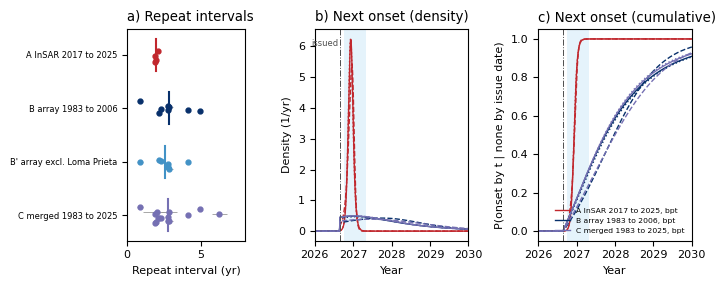

In [7]:
# Figure 4: repeat intervals per catalogue, and the next-onset density and cumulative probability
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9), width_ratios=[1.0, 1.3, 1.3])
cols = {"A_insar": "#C1272D", "B_aa_dense": "#08306B", "B_aa_dense_noLP": "#4292C6", "C_merged": "#7570B3"}
labels = {"A_insar": "A InSAR 2017 to 2025", "B_aa_dense": "B array 1983 to 2006", "B_aa_dense_noLP": "B' array excl. Loma Prieta", "C_merged": "C merged 1983 to 2025"}
ax = axes[0]
for j, (cname, (cat, drop_lp)) in enumerate(catalogs.items()):
    o = cat.onset_yr.values; ivc = intervals_from(o, drop_lp)
    w_ = 0.5 * ((cat.onset_hi - cat.onset_lo).values[1:] + (cat.onset_hi - cat.onset_lo).values[:-1])
    if drop_lp:
        w_ = w_[~((o[:-1] < loma_prieta) & (o[1:] > loma_prieta))]
    ax.errorbar(ivc, j + rng.uniform(-0.15, 0.15, len(ivc)), xerr=w_, fmt="o", ms=3.5, color=cols[cname], ecolor="0.6", elinewidth=0.6)
    ax.plot([np.mean(ivc)] * 2, [j - 0.3, j + 0.3], "-", color=cols[cname], lw=1.5)
ax.set_yticks(range(len(catalogs))); ax.set_yticklabels([labels[c] for c in catalogs], fontsize=6); ax.invert_yaxis()
ax.set_xlim(0, 8); ax.set_xlabel("Repeat interval (yr)"); ax.set_title("a) Repeat intervals", loc="left")
wet_y = decyear(pd.to_datetime(list(wet)))
for ax, kind, ttl in [(axes[1], "pdf", "b) Next onset (density)"), (axes[2], "cdf", "c) Next onset (cumulative)")]:
    ax.axvspan(wet_y[0], wet_y[1], color="#56B4E9", alpha=0.15, lw=0)
    for cname in ["A_insar", "B_aa_dense", "C_merged"]:
        for m, ls in [("bpt", "-"), ("weibull", "--"), ("lognormal", ":")]:
            cdf = curves[(cname, m, "issue")]
            y_ = cdf if kind == "cdf" else np.gradient(cdf, grid)
            ax.plot(grid, y_, ls, color=cols[cname], lw=1.0, label=f"{labels[cname]}, {m}" if m == "bpt" else None)
    ax.axvline(refs["issue"], color="0.3", lw=0.7, ls="-.")
    ax.set_xlim(2026.0, 2030.0); ax.set_xlabel("Year"); ax.set_title(ttl, loc="left")
    ax.set_ylabel("Density (1/yr)" if kind == "pdf" else "P(onset by t | none by issue date)")
axes[2].legend(fontsize=5.5, loc="lower right", frameon=False)
axes[1].text(refs["issue"] - 0.03, axes[1].get_ylim()[1] * 0.95, "issued", fontsize=6, color="0.3", va="top", ha="right")
fig.tight_layout()
f_fc = os.path.join(fig_dir, f"fig4_recurrence_forecast_ntiming{n_timing}_nboot{n_boot}_issue{forecast_issue_date}.png")
fig.savefig(f_fc, dpi=300); fig.savefig(f_fc.replace(".png", ".pdf")); print("Saved Fig 4 to:", f_fc)
plt.show()

## Rainfall conditioning of the onset timing

Every quantity is a range over the onset window (the event is equally likely
anywhere in it). Rule A: lag after the water-year cumulative first exceeds
Y mm. Rule B: lag after the first 3-day storm of at least Z mm. Rule C: a
3-day storm of at least Z mm ended within X days before some day of the
window, scored against the fraction of wet-season days such a window covers,
so five hits out of five can be weighed against chance. The calendar spread
of the InSAR onsets is the baseline any rule has to beat.

In [8]:
def dowy_of(date):
    wy_ = date.year + (1 if date.month >= 10 else 0)
    return (date - pd.Timestamp(f"{wy_ - 1}-10-01")).days + 1, wy_


def wy_series(wy_):
    d = tab[tab.wy == wy_].copy()
    d["cum"] = d.prcp_mm.fillna(0).cumsum(); d["storm"] = d.prcp_mm.fillna(0).rolling(storm_days, min_periods=1).sum()
    return d


def first_date(d, col, thr):
    hit = d.index[d[col] >= thr]; return hit[0] if len(hit) else pd.NaT


p_all = tab.prcp_mm.fillna(0); storm_all = p_all.rolling(storm_days, min_periods=1).sum()
ctx = pd.DataFrame(index=tab.index)
ctx["rain_30d"] = p_all.rolling(30, min_periods=1).sum(); ctx["max_storm_30d"] = storm_all.rolling(30, min_periods=1).max()
last_storm = pd.Series(np.where(storm_all >= 20, np.arange(len(tab)), np.nan), index=tab.index).ffill()
ctx["days_since_storm20"] = np.arange(len(tab)) - last_storm

events = pd.concat([dense[["onset_lo", "onset_hi"]].assign(source="AA"), ins[["onset_lo", "onset_hi"]].assign(source="InSAR")]).sort_values("onset_lo").reset_index(drop=True)
et_rows = []
for e in events.itertuples():
    lo, hi = decyear_to_date(e.onset_lo)[0], decyear_to_date(e.onset_hi)[0]
    _, wy_ = dowy_of(hi); d = wy_series(wy_)
    row = dict(source=e.source, onset_lo=lo.date(), onset_hi=hi.date(), window_days=(hi - lo).days, wy=wy_,
               dowy_lo=dowy_of(lo)[0], dowy_hi=dowy_of(hi)[0], wy_total_mm=float(d.cum.iloc[-1]),
               cum_at_lo=float(d.cum.asof(lo)) if lo >= d.index[0] else 0.0, cum_at_hi=float(d.cum.asof(hi)), gauge=d.src.mode().iloc[0])
    row["frac_at_hi"] = row["cum_at_hi"] / row["wy_total_mm"]
    w_ = ctx.loc[lo:hi]
    for c in ("rain_30d", "max_storm_30d", "days_since_storm20"):
        row[f"{c}_min"] = float(w_[c].min()); row[f"{c}_max"] = float(w_[c].max())
    for Y in y_grid:
        t_ = first_date(d, "cum", Y); row[f"lagY{Y}_lo"] = (lo - t_).days if pd.notna(t_) else np.nan; row[f"lagY{Y}_hi"] = (hi - t_).days if pd.notna(t_) else np.nan
    for Z in z_grid:
        t_ = first_date(d, "storm", Z); row[f"lagZ{Z}_lo"] = (lo - t_).days if pd.notna(t_) else np.nan; row[f"lagZ{Z}_hi"] = (hi - t_).days if pd.notna(t_) else np.nan
    et_rows.append(row)
et = pd.DataFrame(et_rows)
et.to_csv(os.path.join(out_dir, "precip_conditioning_events.csv"), index=False, float_format="%.1f")


def rule_scores(kind, thr_grid):
    ins_t, aa_t = et[et.source == "InSAR"], et[et.source != "InSAR"]; out = []
    for th in thr_grid:
        lo, hi = ins_t[f"lag{kind}{th}_lo"], ins_t[f"lag{kind}{th}_hi"]
        if lo.isna().any():
            out.append(dict(kind=kind, thr=th, n_insar_reached=int(lo.notna().sum()))); continue
        x_lo, x_hi = int(lo.min()), int(hi.max())
        alo, ahi = aa_t[f"lag{kind}{th}_lo"], aa_t[f"lag{kind}{th}_hi"]
        reached = alo.notna(); consistent = reached & (ahi >= x_lo) & (alo <= x_hi)
        cross = {}
        for wy_ in range(wy_years[0], wy_years[1] + 1):
            t_ = first_date(wy_series(wy_), "cum" if kind == "Y" else "storm", th)
            cross[wy_] = dowy_of(t_)[0] if pd.notna(t_) else np.nan
        cross = pd.Series(cross)
        out.append(dict(kind=kind, thr=th, n_insar_reached=5, insar_lag_min=x_lo, insar_lag_max=x_hi, insar_lag_spread=x_hi - x_lo,
                        aa_reached=int(reached.sum()), aa_consistent=int(consistent.sum()), wy_reached_frac=float(cross.notna().mean()),
                        cross_dowy_median=float(cross.median()), cross_dowy_10=float(cross.quantile(.1)), cross_dowy_90=float(cross.quantile(.9))))
    return pd.DataFrame(out)


sc = pd.concat([rule_scores("Y", y_grid), rule_scores("Z", z_grid)])
sc.to_csv(os.path.join(out_dir, "precip_conditioning_thresholds.csv"), index=False, float_format="%.2f")

wet_mask = (tab.dowy >= wet_dowy[0]) & (tab.dowy <= wet_dowy[1]) & (tab.wy >= wy_years[0])
rc_rows = []
for Z in c_z:
    for X in c_x:
        rec = (storm_all >= Z).rolling(X + 1, min_periods=1).max().astype(bool)
        hits = {r.Index: bool(rec.loc[pd.Timestamp(r.onset_lo):pd.Timestamp(r.onset_hi)].any()) for r in et.itertuples()}
        ins_t, aa_t = et[et.source == "InSAR"], et[et.source != "InSAR"]
        p_chance = 1.0
        for r in ins_t.itertuples():
            dil = rec[tab.wy == r.wy].rolling(max(int(r.window_days), 1), min_periods=1).max().astype(bool)
            p_chance *= float(dil[wet_mask & (tab.wy == r.wy)].mean())
        rc_rows.append(dict(Z=Z, X=X, base_rate=float(rec[wet_mask].mean()), insar_hits=sum(hits[i] for i in ins_t.index),
                            aa_hits=sum(hits[i] for i in aa_t.index), p_chance_all_insar=p_chance))
rc = pd.DataFrame(rc_rows)
rc.to_csv(os.path.join(out_dir, "precip_conditioning_ruleC.csv"), index=False, float_format="%.3f")

ins_t, aa_t = et[et.source == "InSAR"], et[et.source == "AA"]
cal_spread = int(ins_t.dowy_hi.max() - ins_t.dowy_lo.min())
wyt = tab.groupby("wy").prcp_mm.sum(min_count=1); wyt = wyt[(wyt.index >= wy_years[0]) & (wyt.index <= 2025)]
dowy_label = lambda d: "--" if not np.isfinite(d) else (pd.Timestamp("2000-10-01") + pd.Timedelta(days=int(d) - 1)).strftime("%b %d")
L += ["", "RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)"]
for r in et.itertuples():
    L.append(f"  {r.source:<5} {r.onset_lo}..{r.onset_hi} ({r.window_days:3d} d) WY{r.wy} total {r.wy_total_mm:5.0f} mm (P{(wyt < r.wy_total_mm).mean() * 100:2.0f}) | "
             f"cum {r.cum_at_lo:4.0f}-{r.cum_at_hi:4.0f} mm, frac {r.frac_at_hi:.2f} | rain 30 d {r.rain_30d_min:3.0f}-{r.rain_30d_max:3.0f} mm, "
             f"max 3-d storm {r.max_storm_30d_min:3.0f}-{r.max_storm_30d_max:3.0f} mm, {r.days_since_storm20_min:3.0f}-{r.days_since_storm20_max:3.0f} d since >= 20 mm storm [{r.gauge}]")
L += [f"InSAR events: WY totals {ins_t.wy_total_mm.min():.0f}-{ins_t.wy_total_mm.max():.0f} mm (" + ", ".join(f"P{(wyt < v).mean() * 100:.0f}" for v in ins_t.wy_total_mm) + ")",
      f"InSAR onsets: day-of-WY {ins_t.dowy_lo.min():.0f}-{ins_t.dowy_hi.max():.0f} ({dowy_label(ins_t.dowy_lo.min())}-{dowy_label(ins_t.dowy_hi.max())}), calendar spread {cal_spread} d",
      f"InSAR onsets: WY rain accumulated by the onset {ins_t.cum_at_lo.min():.0f}-{ins_t.cum_at_hi.max():.0f} mm, fraction of the WY total {ins_t.frac_at_hi.min():.2f}-{ins_t.frac_at_hi.max():.2f}",
      "rule A (lag after WY cumulative exceeds Y):"]
for r in sc[sc.kind == "Y"].itertuples():
    L.append(f"  Y={r.thr:4.0f} mm: " + (f"reached in only {r.n_insar_reached}/5 InSAR event years -> no rule" if r.n_insar_reached < 5 else
             f"lag {r.insar_lag_min:4.0f}..{r.insar_lag_max:4.0f} d (spread {r.insar_lag_spread:3.0f} d) | AA consistent {r.aa_consistent:.0f}/{r.aa_reached:.0f} | "
             f"reached in {r.wy_reached_frac * 100:3.0f}% of WYs, crossing {dowy_label(r.cross_dowy_median)}"))
L.append("rule B (lag after the first 3-day storm >= Z):")
for r in sc[sc.kind == "Z"].itertuples():
    L.append(f"  Z={r.thr:4.0f} mm: " + (f"reached in only {r.n_insar_reached}/5 InSAR event years -> no rule" if r.n_insar_reached < 5 else
             f"lag {r.insar_lag_min:4.0f}..{r.insar_lag_max:4.0f} d (spread {r.insar_lag_spread:3.0f} d) | AA consistent {r.aa_consistent:.0f}/{r.aa_reached:.0f} | "
             f"first storm {dowy_label(r.cross_dowy_median)}"))
L.append("rule C (3-day storm >= Z within X d before some day of the window; base = fraction of Dec-Mar days covered; P(chance) = all 5 InSAR windows hit by calendar alone):")
for r in rc.itertuples():
    L.append(f"  Z={r.Z:3d} mm, X={r.X:2d} d: InSAR {r.insar_hits}/5, AA {r.aa_hits}/9 | base rate {r.base_rate:.2f}, P(chance 5/5) {r.p_chance_all_insar:.2f}")
rc5 = rc[rc.insar_hits == 5]; bestC = rc5.sort_values("p_chance_all_insar").iloc[0] if len(rc5) else None
ok = sc[sc.n_insar_reached == 5]
bestY = ok[ok.kind == "Y"].sort_values("insar_lag_spread").iloc[0]; bestZ = ok[ok.kind == "Z"].sort_values("insar_lag_spread").iloc[0]
L += [f"tightest rules: A Y={bestY.thr:.0f} mm lag {bestY.insar_lag_min:.0f}..{bestY.insar_lag_max:.0f} d (spread {bestY.insar_lag_spread:.0f} vs calendar {cal_spread} d); "
      f"B Z={bestZ.thr:.0f} mm lag {bestZ.insar_lag_min:.0f}..{bestZ.insar_lag_max:.0f} d (spread {bestZ.insar_lag_spread:.0f} d); "
      + (f"C Z={bestC.Z:.0f} mm within X={bestC.X:.0f} d: InSAR 5/5, AA {bestC.aa_hits:.0f}/9, base rate {bestC.base_rate:.2f}, P(chance) {bestC.p_chance_all_insar:.2f}" if bestC is not None else "C: none hits all five")]
print("\n".join(L[L.index("RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)"):]))

RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end; antecedent quantities are min-max over the window)
  AA    1983-01-18..1983-05-21 (123 d) WY1983 total   738 mm (P96) | cum  211- 710 mm, frac 0.96 | rain 30 d  28-218 mm, max 3-d storm  20- 71 mm,   0- 30 d since >= 20 mm storm [NEWARK]
  AA    1985-12-14..1986-03-09 ( 85 d) WY1986 total   444 mm (P74) | cum  115- 353 mm, frac 0.80 | rain 30 d  27-156 mm, max 3-d storm  20- 48 mm,   0- 29 d since >= 20 mm storm [NEWARK]
  AA    1988-04-16..1988-05-30 ( 43 d) WY1988 total   213 mm (P 9) | cum  180- 211 mm, frac 0.99 | rain 30 d   7- 32 mm, max 3-d storm   6- 13 mm,  90-133 d since >= 20 mm storm [NEWARK]
  AA    1993-03-06..1993-05-09 ( 63 d) WY1993 total   546 mm (P87) | cum  442- 524 mm, frac 0.96 | rain 30 d  14-121 mm, max 3-d storm  10- 58 mm,   0- 43 d since >= 20 mm storm [NEWARK]
  AA    1997-04-27..1997-06-21 ( 55 d) WY1997 total   408 mm (P61) | cum  382- 395 mm, frac 0.97 | rain 30 d   0- 13 mm, 

In [9]:
# the prediction statement, from the numbers above (the format of the legacy run22)
A = fc[(fc.catalog == "A_insar") & (fc.ref == "issue")].set_index("model")
B = fc[(fc.catalog == "B_aa_dense") & (fc.ref == "issue")].set_index("model")
C = fc[(fc.catalog == "C_merged") & (fc.ref == "issue")].set_index("model")
S = ["TULE POND CREEP-EVENT PREDICTION STATEMENT (generated by notebook 09; the wording is the legacy run22 template)",
     f"issued {forecast_issue_date}; data: OPERA DISP-S1 to {ref_dates['data_end']}, HRKT alignment array to {aa.onset_hi.max():.2f}, Fremont GHCN gauge to {tab.index[tab.prcp_mm.notna()].max().date()}", "",
     "LOCATION  Hayward fault, Tule Pond section (see notebook 04 for the measured extent)",
     f"MAGNITUDE surface slip {ins.amplitude_mm.min():.1f}-{ins.amplitude_mm.max():.1f} mm on the stack (five InSAR events; 95% CIs {ins.amp_lo.min():.1f}-{ins.amp_hi.max():.1f} mm), within one 6-12 d acquisition interval", "",
     "TIME WINDOW",
     f"  (1) InSAR clock alone ({n_iv} intervals, mean {iv.mean():.2f} yr, sd {iv.std(ddof=1) * 365.25:.0f} d): next = last + mean = {ymd(nxt)}; +/-1 sd {ymd(nxt - iv.std(ddof=1))}..{ymd(nxt + iv.std(ddof=1))}; "
     f"95% prediction interval (t, n={n_iv}) {ymd(nxt - half)}..{ymd(nxt + half)}",
     f"      renewal models (BPT, bootstrap): 5-95% {A.loc['bpt', 'q05']} .. {A.loc['bpt', 'q95']}, median {A.loc['bpt', 'q50']}; P(WY2027 wet season) = {A.loc['bpt', 'p_wet_season']:.2f}",
     f"  (2) 45-yr alignment-array record: dense era BPT 5-95% {B.loc['bpt', 'q05']} .. {B.loc['bpt', 'q95']}, median {B.loc['bpt', 'q50']}; P(WY2027 wet season) = {B.loc['bpt', 'p_wet_season']:.2f}, P(by end 2027) = {B.loc['bpt', 'p_by_2027']:.2f}",
     f"      merged BPT 5-95% {C.loc['bpt', 'q05']} .. {C.loc['bpt', 'q95']}, median {C.loc['bpt', 'q50']}; P(WY2027 wet season) = {C.loc['bpt', 'p_wet_season']:.2f}; Poisson null {C.loc['exponential', 'p_wet_season']:.2f}",
     f"  (3) all five InSAR onsets fell {int(ins_t.dowy_lo.min())}-{int(ins_t.dowy_hi.max())} d into the water year ({dowy_label(ins_t.dowy_lo.min())}-{dowy_label(ins_t.dowy_hi.max())}), "
     f"after {ins_t.cum_at_lo.min():.0f}-{ins_t.cum_at_hi.max():.0f} mm of WY rain ({ins_t.frac_at_hi.min():.0%}-{ins_t.frac_at_hi.max():.0%} of the WY total), in years spanning "
     f"P{(wyt < ins_t.wy_total_mm.min()).mean() * 100:.0f}-P{(wyt < ins_t.wy_total_mm.max()).mean() * 100:.0f} of the 1980-2025 WY-total distribution",
     (f"      rule C: a 3-day storm >= {bestC.Z:.0f} mm within {bestC.X:.0f} d before onset (5/5 InSAR, {bestC.aa_hits:.0f}/9 AA); such windows cover {bestC.base_rate:.0%} of Dec-Mar days, P(5/5 by chance) = {bestC.p_chance_all_insar:.2f}" if bestC is not None else "      rule C: none"),
     f"      rules A and B do not tighten the window beyond the calendar spread ({cal_spread} d)"]
with open(os.path.join(out_dir, "prediction_statement.txt"), "w") as fh:
    fh.write("\n".join(S) + "\n")
print("\n".join(S))

TULE POND CREEP-EVENT PREDICTION STATEMENT (generated by notebook 09; the wording is the legacy run22 template)
issued 2026-08-25; data: OPERA DISP-S1 to 2025-12-21, HRKT alignment array to 2023.86, Fremont GHCN gauge to 2026-08-21

LOCATION  Hayward fault, Tule Pond section (see notebook 04 for the measured extent)
MAGNITUDE surface slip 6.6-9.1 mm on the stack (five InSAR events; 95% CIs 5.9-10.1 mm), within one 6-12 d acquisition interval

TIME WINDOW
  (1) InSAR clock alone (4 intervals, mean 1.97 yr, sd 30 d): next = last + mean = 2026-12-15; +/-1 sd 2026-11-15..2027-01-14; 95% prediction interval (t, n=4) 2026-08-29..2027-04-02
      renewal models (BPT, bootstrap): 5-95% 2026-10-28 .. 2027-01-21, median 2026-12-09; P(WY2027 wet season) = 0.99
  (2) 45-yr alignment-array record: dense era BPT 5-95% 2026-10-04 .. 2030-11-14, median 2027-10-01; P(WY2027 wet season) = 0.28, P(by end 2027) = 0.59
      merged BPT 5-95% 2026-10-04 .. 2030-07-23, median 2027-09-24; P(WY2027 wet season)

Saved figure to: /Users/dlindsay/tools/internal/TulePond_DISP/Figures_2026-09-21/figS_precip_conditioning_storm3d_bestY125mm.png


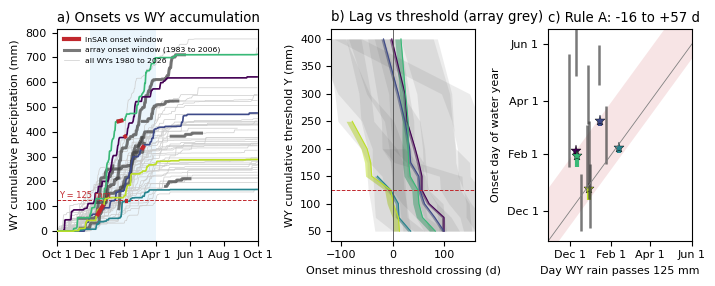

In [10]:
# Supplementary figure: WY accumulation with onsets; lag vs threshold; onset vs crossing day (rule A)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.9), width_ratios=[1.4, 1.0, 1.0])
ax = axes[0]
ax.axvspan(*wet_dowy, color="#56B4E9", alpha=0.12, lw=0)
for wy_ in range(wy_years[0], wy_years[1] + 1):
    d = wy_series(wy_); ax.plot(d.dowy, d.cum, "-", color="0.8", lw=0.5, zorder=1)
colsv = plt.cm.viridis(np.linspace(0, 0.9, len(ins_t)))
for c, r in zip(colsv, ins_t.itertuples()):
    d = wy_series(r.wy); ax.plot(d.dowy, d.cum, "-", color=c, lw=1.2, zorder=3, label=f"WY{r.wy}")
    ax.plot([r.dowy_lo, r.dowy_hi], [r.cum_at_lo, r.cum_at_hi], "-", color="#C1272D", lw=3, solid_capstyle="butt", zorder=4)
for r in aa_t.itertuples():
    d = wy_series(r.wy); seg = d[(d.dowy >= r.dowy_lo) & (d.dowy <= r.dowy_hi)]
    ax.plot(seg.dowy, seg.cum, "-", color="0.25", lw=2.2, alpha=0.7, zorder=2)
ax.axhline(bestY.thr, color="#C1272D", lw=0.7, ls="--"); ax.text(5, bestY.thr + 8, f"Y = {bestY.thr:.0f} mm", fontsize=6, color="#C1272D")
ax.set_xlim(1, 366); ax.set_xticks([1, 62, 124, 182, 244, 305, 366]); ax.set_xticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_ylabel("WY cumulative precipitation (mm)")
ax.legend(handles=[Line2D([], [], color="#C1272D", lw=3, label="InSAR onset window"), Line2D([], [], color="0.25", lw=2.2, alpha=0.7, label="array onset window (1983 to 2006)"),
                   Line2D([], [], color="0.8", lw=0.5, label="all WYs 1980 to 2026")], fontsize=5.5, loc="upper left", frameon=False)
ax.set_title("a) Onsets vs WY accumulation", loc="left")
ax = axes[1]
ys = [r.thr for r in sc[sc.kind == "Y"].itertuples()]
for c, r in zip(colsv, ins_t.itertuples()):
    lo = [r._asdict()[f"lagY{Y}_lo"] for Y in ys]; hi = [r._asdict()[f"lagY{Y}_hi"] for Y in ys]
    ax.fill_betweenx(ys, lo, hi, color=c, alpha=0.5, lw=0); ax.plot(hi, ys, "-", color=c, lw=0.8)
for r in aa_t.itertuples():
    lo = [r._asdict()[f"lagY{Y}_lo"] for Y in ys]; hi = [r._asdict()[f"lagY{Y}_hi"] for Y in ys]
    ax.fill_betweenx(ys, lo, hi, color="0.3", alpha=0.10, lw=0)
ax.axvline(0, color="0.3", lw=0.6); ax.axhline(bestY.thr, color="#C1272D", lw=0.7, ls="--")
ax.set_xlim(-120, 160); ax.set_xlabel("Onset minus threshold crossing (d)"); ax.set_ylabel("WY cumulative threshold Y (mm)"); ax.set_title("b) Lag vs threshold (array grey)", loc="left")
ax = axes[2]
Yb = int(bestY.thr)
for c, r in zip(colsv, ins_t.itertuples()):
    x_ = r.dowy_hi - r._asdict()[f"lagY{Yb}_hi"]
    ax.plot([x_, x_], [r.dowy_lo, r.dowy_hi], "-", color=c, lw=3, solid_capstyle="butt"); ax.plot(x_, r.dowy_hi, "*", color=c, ms=8, mec="k", mew=0.3)
for r in aa_t.itertuples():
    v = r._asdict()[f"lagY{Yb}_hi"]
    if np.isfinite(v):
        x_ = r.dowy_hi - v; ax.plot([x_, x_], [r.dowy_lo, r.dowy_hi], "-", color="0.25", lw=1.8, alpha=0.7, solid_capstyle="butt")
xx = np.array([1, 366]); ax.plot(xx, xx, "-", color="0.5", lw=0.6)
ax.fill_between(xx, xx + bestY.insar_lag_min, xx + bestY.insar_lag_max, color="#C1272D", alpha=0.12, lw=0)
ax.set_xlim(30, 220); ax.set_ylim(30, 260); tk = [62, 124, 182, 244]; tl = ["Dec 1", "Feb 1", "Apr 1", "Jun 1"]
ax.set_xticks(tk); ax.set_xticklabels(tl); ax.set_yticks(tk); ax.set_yticklabels(tl)
ax.set_xlabel(f"Day WY rain passes {Yb} mm"); ax.set_ylabel("Onset day of water year"); ax.set_title(f"c) Rule A: {bestY.insar_lag_min:+.0f} to {bestY.insar_lag_max:+.0f} d", loc="left")
fig.tight_layout()
f_cond = os.path.join(fig_dir, f"figS_precip_conditioning_storm{storm_days}d_bestY{Yb}mm.png")
fig.savefig(f_cond, dpi=300); fig.savefig(f_cond.replace(".png", ".pdf")); print("Saved figure to:", f_cond)
plt.show()

## REGISTER

In [11]:
sidecar = REG.sidecar("09_forecast", L + ["", *S])
REG.register("09_issue_date", forecast_issue_date, "date", 0, where="P10, M9", cell="constants", sidecar=sidecar)
REG.register("09_rain_series_start", str(days[0].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_wy_median_mm", comp.total_mm.median(), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_wy_p10_mm", comp.total_mm.quantile(.1), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_wy_p90_mm", comp.total_mm.quantile(.9), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("09_n_aa_season_resolved", len(dense), "count", 0, where="Fig3 caption", cell="catalogues", sidecar=sidecar)
REG.register("09_n_aa_dec_mar", winter(dense), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("09_n_insar_dec_mar", winter(ins), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register("09_insar_interval_mean_yr", iv.mean(), "yr", 2, where="P10", cell="clock", sidecar=sidecar)
REG.register("09_insar_interval_sd_d", iv.std(ddof=1) * 365.25, "d", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("09_insar_interval_sd_ci_lo_d", sd_ci[0], "d", 0, where="M9", cell="clock", sidecar=sidecar)
REG.register("09_insar_interval_sd_ci_hi_d", sd_ci[1], "d", 0, where="M9", cell="clock", sidecar=sidecar)
REG.register("09_insar_cov", iv.std(ddof=1) / iv.mean(), "1", 2, where="P10", cell="clock", sidecar=sidecar)
REG.register("09_next_clock_date", ymd(nxt), "date", 0, where="P10, Fig4", cell="clock", sidecar=sidecar)
REG.register("09_next_1sd_lo", ymd(nxt - iv.std(ddof=1)), "date", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("09_next_1sd_hi", ymd(nxt + iv.std(ddof=1)), "date", 0, where="P10", cell="clock", sidecar=sidecar)
REG.register("09_pi95_lo", ymd(nxt - half), "date", 0, where="P10, Fig4", cell="clock", sidecar=sidecar)
REG.register("09_pi95_hi", ymd(nxt + half), "date", 0, where="P10, Fig4", cell="clock", sidecar=sidecar)
for cname, key in (("A_insar", "insar"), ("B_aa_dense", "aa_dense"), ("B_aa_dense_noLP", "aa_dense_nolp"), ("C_merged", "merged")):
    sub = fc[(fc.catalog == cname) & (fc.ref == "issue")].set_index("model")
    for m in ("bpt", "lognormal", "weibull", "exponential"):
        REG.register(f"09_{key}_{m}_q05", sub.loc[m, "q05"], "date", 0, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"09_{key}_{m}_q50", sub.loc[m, "q50"], "date", 0, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"09_{key}_{m}_q95", sub.loc[m, "q95"], "date", 0, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"09_{key}_{m}_p_wet_wy2027", sub.loc[m, "p_wet_season"], "1", 2, where="P10, Fig4", cell="forecast", sidecar=sidecar)
        REG.register(f"09_{key}_{m}_p_by_end_2027", sub.loc[m, "p_by_2027"], "1", 2, where="P10", cell="forecast", sidecar=sidecar)
        REG.register(f"09_{key}_{m}_daicc", sub.loc[m, "daicc"], "1", 2, where="M9", cell="forecast", sidecar=sidecar)
    REG.register(f"09_{key}_n_intervals", int(sub.n_intervals.iloc[0]), "count", 0, where="M9", cell="forecast", sidecar=sidecar)
    REG.register(f"09_{key}_interval_mean_yr", float(sub.loc["bpt", "mean_yr"]), "yr", 2, where="P10", cell="forecast", sidecar=sidecar)
    REG.register(f"09_{key}_interval_cov", float(sub.loc["bpt", "cov"]), "1", 2, where="P10", cell="forecast", sidecar=sidecar)
REG.register("09_onset_dowy_min", int(ins_t.dowy_lo.min()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_onset_dowy_max", int(ins_t.dowy_hi.max()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_onset_earliest", dowy_label(ins_t.dowy_lo.min()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_onset_latest", dowy_label(ins_t.dowy_hi.max()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_onset_calendar_spread_d", cal_spread, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_wy_total_min_mm", ins_t.wy_total_mm.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_wy_total_max_mm", ins_t.wy_total_mm.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_wy_percentile_min", (wyt < ins_t.wy_total_mm.min()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_wy_percentile_max", (wyt < ins_t.wy_total_mm.max()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_cum_at_onset_min_mm", ins_t.cum_at_lo.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_cum_at_onset_max_mm", ins_t.cum_at_hi.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_frac_at_onset_min", ins_t.frac_at_hi.min(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_frac_at_onset_max", ins_t.frac_at_hi.max(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_ruleA_best_Y_mm", bestY.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_ruleA_lag_min_d", bestY.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_ruleA_lag_max_d", bestY.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_ruleB_best_Z_mm", bestZ.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_ruleB_lag_min_d", bestZ.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("09_ruleB_lag_max_d", bestZ.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
if bestC is not None:
    REG.register("09_ruleC_Z_mm", bestC.Z, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("09_ruleC_X_d", bestC.X, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("09_ruleC_insar_hits", bestC.insar_hits, "count", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("09_ruleC_aa_hits", bestC.aa_hits, "count", 0, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("09_ruleC_base_rate", bestC.base_rate, "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
    REG.register("09_ruleC_p_chance", bestC.p_chance_all_insar, "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/09_seasonality_forecast/09_forecast_stats.txt
  registered 09_issue_date = 2026-08-25 date  -> P10, M9
  registered 09_rain_series_start = 1978-10-01 date  -> M9
  registered 09_wy_median_mm = 362 mm  -> M9
  registered 09_wy_p10_mm = 219 mm  -> M9
  registered 09_wy_p90_mm = 567 mm  -> M9
  registered 09_n_aa_season_resolved = 9 count  -> Fig3 caption
  registered 09_n_aa_dec_mar = 6 count  -> P10
  registered 09_n_insar_dec_mar = 5 count  -> P10
  registered 09_insar_interval_mean_yr = 1.97 yr  -> P10
  registered 09_insar_interval_sd_d = 30 d  -> P10
  registered 09_insar_interval_sd_ci_lo_d = 17 d  -> M9
  registered 09_insar_interval_sd_ci_hi_d = 113 d  -> M9
  registered 09_insar_cov = 0.04 1  -> P10
  registered 09_next_clock_date = 2026-12-15 date  -> P10, Fig4
  registered 09_next_1sd_lo = 2026-11-15 date  -> P10
  registered 09_next_1sd_hi = 2027-01-14 date  -> P10
  registered 09_pi95_lo = 2026-08-29 date  

  registered 09_insar_bpt_p_by_end_2027 = 1.00 1  -> P10
  registered 09_insar_bpt_daicc = 0.00 1  -> M9
  registered 09_insar_lognormal_q05 = 2026-10-27 date  -> P10, Fig4
  registered 09_insar_lognormal_q50 = 2026-12-08 date  -> P10, Fig4
  registered 09_insar_lognormal_q95 = 2027-01-21 date  -> P10, Fig4
  registered 09_insar_lognormal_p_wet_wy2027 = 0.99 1  -> P10, Fig4
  registered 09_insar_lognormal_p_by_end_2027 = 1.00 1  -> P10
  registered 09_insar_lognormal_daicc = 0.00 1  -> M9
  registered 09_insar_weibull_q05 = 2026-10-11 date  -> P10, Fig4
  registered 09_insar_weibull_q50 = 2026-12-12 date  -> P10, Fig4
  registered 09_insar_weibull_q95 = 2027-01-22 date  -> P10, Fig4
  registered 09_insar_weibull_p_wet_wy2027 = 0.97 1  -> P10, Fig4
  registered 09_insar_weibull_p_by_end_2027 = 1.00 1  -> P10
  registered 09_insar_weibull_daicc = 1.03 1  -> M9
  registered 09_insar_exponential_q05 = 2026-09-23 date  -> P10, Fig4
  registered 09_insar_exponential_q50 = 2027-11-01 date  ->

  registered 09_insar_exponential_p_wet_wy2027 = 0.28 1  -> P10, Fig4
  registered 09_insar_exponential_p_by_end_2027 = 0.54 1  -> P10
  registered 09_insar_exponential_daicc = 10.58 1  -> M9
  registered 09_insar_n_intervals = 4 count  -> M9
  registered 09_insar_interval_mean_yr = 1.97 yr  -> P10
  registered 09_insar_interval_cov = 0.04 1  -> P10
  registered 09_aa_dense_bpt_q05 = 2026-10-04 date  -> P10, Fig4
  registered 09_aa_dense_bpt_q50 = 2027-10-01 date  -> P10, Fig4
  registered 09_aa_dense_bpt_q95 = 2030-11-14 date  -> P10, Fig4
  registered 09_aa_dense_bpt_p_wet_wy2027 = 0.28 1  -> P10, Fig4
  registered 09_aa_dense_bpt_p_by_end_2027 = 0.59 1  -> P10
  registered 09_aa_dense_bpt_daicc = 2.90 1  -> M9
  registered 09_aa_dense_lognormal_q05 = 2026-10-07 date  -> P10, Fig4
  registered 09_aa_dense_lognormal_q50 = 2027-10-13 date  -> P10, Fig4
  registered 09_aa_dense_lognormal_q95 = 2030-12-14 date  -> P10, Fig4
  registered 09_aa_dense_lognormal_p_wet_wy2027 = 0.27 1  -> P10

  registered 09_aa_dense_weibull_p_by_end_2027 = 0.51 1  -> P10
  registered 09_aa_dense_weibull_daicc = 0.00 1  -> M9
  registered 09_aa_dense_exponential_q05 = 2026-10-11 date  -> P10, Fig4
  registered 09_aa_dense_exponential_q50 = 2028-06-21 date  -> P10, Fig4
  registered 09_aa_dense_exponential_q95 = 2030-12-31 date  -> P10, Fig4
  registered 09_aa_dense_exponential_p_wet_wy2027 = 0.19 1  -> P10, Fig4
  registered 09_aa_dense_exponential_p_by_end_2027 = 0.41 1  -> P10
  registered 09_aa_dense_exponential_daicc = 3.78 1  -> M9
  registered 09_aa_dense_n_intervals = 8 count  -> M9
  registered 09_aa_dense_interval_mean_yr = 2.84 yr  -> P10
  registered 09_aa_dense_interval_cov = 0.52 1  -> P10
  registered 09_aa_dense_nolp_bpt_q05 = 2026-09-23 date  -> P10, Fig4
  registered 09_aa_dense_nolp_bpt_q50 = 2027-07-08 date  -> P10, Fig4
  registered 09_aa_dense_nolp_bpt_q95 = 2030-01-30 date  -> P10, Fig4
  registered 09_aa_dense_nolp_bpt_p_wet_wy2027 = 0.34 1  -> P10, Fig4
  registered 

  registered 09_aa_dense_nolp_lognormal_q05 = 2026-09-27 date  -> P10, Fig4
  registered 09_aa_dense_nolp_lognormal_q50 = 2027-07-23 date  -> P10, Fig4
  registered 09_aa_dense_nolp_lognormal_q95 = 2030-02-08 date  -> P10, Fig4
  registered 09_aa_dense_nolp_lognormal_p_wet_wy2027 = 0.33 1  -> P10, Fig4
  registered 09_aa_dense_nolp_lognormal_p_by_end_2027 = 0.67 1  -> P10
  registered 09_aa_dense_nolp_lognormal_daicc = 2.15 1  -> M9
  registered 09_aa_dense_nolp_weibull_q05 = 2026-10-13 date  -> P10, Fig4
  registered 09_aa_dense_nolp_weibull_q50 = 2027-08-31 date  -> P10, Fig4
  registered 09_aa_dense_nolp_weibull_q95 = 2029-01-31 date  -> P10, Fig4
  registered 09_aa_dense_nolp_weibull_p_wet_wy2027 = 0.27 1  -> P10, Fig4
  registered 09_aa_dense_nolp_weibull_p_by_end_2027 = 0.67 1  -> P10
  registered 09_aa_dense_nolp_weibull_daicc = 0.00 1  -> M9
  registered 09_aa_dense_nolp_exponential_q05 = 2026-10-05 date  -> P10, Fig4
  registered 09_aa_dense_nolp_exponential_q50 = 2028-03-31 d

  registered 09_merged_bpt_q95 = 2030-07-23 date  -> P10, Fig4
  registered 09_merged_bpt_p_wet_wy2027 = 0.28 1  -> P10, Fig4
  registered 09_merged_bpt_p_by_end_2027 = 0.60 1  -> P10
  registered 09_merged_bpt_daicc = 0.24 1  -> M9
  registered 09_merged_lognormal_q05 = 2026-10-05 date  -> P10, Fig4
  registered 09_merged_lognormal_q50 = 2027-09-21 date  -> P10, Fig4
  registered 09_merged_lognormal_q95 = 2030-06-26 date  -> P10, Fig4
  registered 09_merged_lognormal_p_wet_wy2027 = 0.28 1  -> P10, Fig4
  registered 09_merged_lognormal_p_by_end_2027 = 0.60 1  -> P10
  registered 09_merged_lognormal_daicc = 0.00 1  -> M9
  registered 09_merged_weibull_q05 = 2026-10-18 date  -> P10, Fig4
  registered 09_merged_weibull_q50 = 2028-01-01 date  -> P10, Fig4
  registered 09_merged_weibull_q95 = 2030-04-22 date  -> P10, Fig4
  registered 09_merged_weibull_p_wet_wy2027 = 0.21 1  -> P10, Fig4
  registered 09_merged_weibull_p_by_end_2027 = 0.50 1  -> P10
  registered 09_merged_weibull_daicc = 2.0

  registered 09_merged_exponential_p_by_end_2027 = 0.40 1  -> P10
  registered 09_merged_exponential_daicc = 12.24 1  -> M9
  registered 09_merged_n_intervals = 15 count  -> M9
  registered 09_merged_interval_mean_yr = 2.78 yr  -> P10
  registered 09_merged_interval_cov = 0.48 1  -> P10
  registered 09_onset_dowy_min = 74 d  -> P10
  registered 09_onset_dowy_max = 160 d  -> P10
  registered 09_onset_earliest = Dec 13 date  -> P10
  registered 09_onset_latest = Mar 09 date  -> P10
  registered 09_onset_calendar_spread_d = 86 d  -> P10
  registered 09_wy_total_min_mm = 168 mm  -> P10
  registered 09_wy_total_max_mm = 712 mm  -> P10
  registered 09_wy_percentile_min = 0 pct  -> P10
  registered 09_wy_percentile_max = 93 pct  -> P10
  registered 09_cum_at_onset_min_mm = 61 mm  -> P10
  registered 09_cum_at_onset_max_mm = 447 mm  -> P10
  registered 09_frac_at_onset_min = 0.37 1  -> P10
  registered 09_frac_at_onset_max = 0.73 1  -> P10
  registered 09_ruleA_best_Y_mm = 125 mm  -> P10
  reg

  registered 09_ruleC_aa_hits = 7 count  -> P10
  registered 09_ruleC_base_rate = 0.27 1  -> P10
  registered 09_ruleC_p_chance = 0.02 1  -> P10
Rendered registry to: /Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/tools/internal/TulePond_DISP/outputs/registry.txt'